# Machine Learning - Grundlagen
## 02 - Tensoren und Operationen

Bevor wir ein einziges Neuron bauen, müssen wir die **Datenstruktur** verstehen, in der alles lebt: den **Tensor**. Das Wort klingt einschüchternd, ist aber im Kern simpel: Ein Tensor ist ein mehrdimensionales Zahlengitter. Skalare, Vektoren und Matrizen sind Spezialfälle - Tensoren verallgemeinern sie auf beliebig viele Dimensionen.

In diesem Notebook arbeiten wir mit **NumPy** - nicht weil es das beste ML-Framework wäre, sondern weil es *genau das tut, was wir hinschreiben*. Jede Operation hier lässt sich 1:1 in C, Rust, PyTorch, TensorFlow oder Papier & Schreiber (wenn du mutig bist) übersetzen. Die Mathematik ist dieselbe.

### Lernziele

- **Tensor-Hierarchie** - Skalar -> Vektor -> Matrix -> Tensor: Shape und Rang
- **Reshaping** - Daten umformen ohne sie zu kopieren
- **Elementweise Operationen** - Addition, Multiplikation, Broadcasting
- **Matmul** - Matrixmultiplikation und ihre Verallgemeinerung auf Batches
- **Reduktionen** - Summe, Mittelwert, Maximum entlang von Achsen
- **Softmax** - von rohen Zahlen zu Wahrscheinlichkeiten

**Voraussetzungen:** [01 - Vektoren](../../Foundations/05_Vektoren_Matrizen/01_Grundlagen_der_Vektoren.ipynb), [02 - Matrizen](../../Foundations/05_Vektoren_Matrizen/02_Matrizen.ipynb)

---

### 1. Was ist ein Tensor?

Ein Tensor ist ein **mehrdimensionales Array** von Zahlen. Die **Anzahl der Dimensionen** heißt **Rang** (engl. *rank* oder *ndim*), die **Größe jeder Dimension** ergibt den **Shape**:

| Rang | Name | Shape-Beispiel | Beispiel |
|------|------|----------------|----------|
| 0 | **Skalar** | `()` | Eine Temperatur: $23{,}5$ |
| 1 | **Vektor** | `(3,)` | Ein Punkt im Raum: $(x, y, z)$ |
| 2 | **Matrix** | `(3, 4)` | Tabelle: 3 Zeilen, 4 Spalten |
| 3 | **3D-Tensor** | `(2, 3, 4)` | Batch von 2 Matrizen |
| $n$ | **$n$ D-Tensor** | $(d_1, d_2, \ldots, d_n)$ | Allgemein |

Die **Gesamtanzahl der Elemente** ist das Produkt aller Dimensionen: Ein Tensor mit Shape $(2, 3, 4)$ enthält $2 \times 3 \times 4 = 24$ Zahlen.

#### Wann braucht man mehr als 2 Dimensionen?

In der Praxis begegnet man höherdimensionalen Tensoren ständig:

| Shape | Bedeutung |
|-------|----------|
| `(N, D)` | Datensatz: $N$ Datenpunkte mit $D$ Features |
| `(B, T, D)` | Textbatch: $B$ Sätze, $T$ Tokens pro Satz, $D$ Embedding-Dimensionen |
| `(B, C, H, W)` | Bilderbatch: $B$ Bilder, $C$ Kanäle (RGB=3), Höhe $H$, Breite $W$ |

Die **Batch-Dimension** $B$ steht konventionell immer vorne. Das ermöglicht es, viele Datenpunkte gleichzeitig zu verarbeiten, ohne Schleifen schreiben zu müssen.

In [1]:
import numpy as np

skalar    = np.float64(23.5)
vektor    = np.array([1.0, 2.0, 3.0])
matrix    = np.array([[1, 2, 3], [4, 5, 6]])
tensor_3d = np.array([[[1, 2], [3, 4], [5, 6]],
                      [[7, 8], [9, 10], [11, 12]]])

for name, t in [("Skalar", skalar), ("Vektor", vektor),
                ("Matrix", matrix), ("3D-Tensor", tensor_3d)]:
    print(f"{name:10s}  shape={str(t.shape):12s}  ndim={t.ndim}  size={t.size}")

Skalar      shape=()            ndim=0  size=1
Vektor      shape=(3,)          ndim=1  size=3
Matrix      shape=(2, 3)        ndim=2  size=6
3D-Tensor   shape=(2, 3, 2)     ndim=3  size=12


### 2. Reshaping - Gleiche Daten, andere Form

Ein Tensor enthält eine feste Menge an Zahlen, die **im Speicher sequenziell** hintereinander liegen. Reshape ändert nur die *Interpretation* dieser Sequenz - keine Daten werden kopiert.

$$\underbrace{[1, 2, 3, 4, 5, 6]}_{6 \text{ Elemente}} \;\xrightarrow{\text{reshape}(2, 3)}\; \begin{pmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \end{pmatrix} \;\xrightarrow{\text{reshape}(3, 2)}\; \begin{pmatrix} 1 & 2 \\ 3 & 4 \\ 5 & 6 \end{pmatrix}$$

**Regel:** Das Produkt aller Dimensionen muss gleich bleiben: $\prod d_i = \prod d_i'$

Einige besonders wichtige Reshape-Operationen haben eigene Namen:

| Operation | Was passiert | Typischer Einsatz |
|-----------|-------------|-------------------|
| `reshape(B, -1)` | Flachklopfen aller Dimensionen außer Batch | Übergang CNN -> Fully Connected |
| `squeeze` | Dimension der Größe 1 entfernen | `(1, 3, 1)` -> `(3,)` |
| `unsqueeze` / `None` | Dimension der Größe 1 einfügen | `(3,)` -> `(1, 3)` oder `(3, 1)` |
| `transpose` | Achsen vertauschen | `(3, 4)` -> `(4, 3)` (= $A^T$) |

In [ ]:
a = np.arange(1, 7)

print(f"Original:      {a}  shape={a.shape}")
print(f"reshape(2,3):  {a.reshape(2, 3).tolist()}")
print(f"reshape(3,2):  {a.reshape(3, 2).tolist()}")
print(f"reshape(2,-1): {a.reshape(2, -1).tolist()}  (-1 wird automatisch berechnet)")

v = np.array([10, 20, 30])
print(f"\nv:          shape={v.shape}")
print(f"v[None, :]: shape={v[np.newaxis, :].shape}  (Zeilenvektor)")
print(f"v[:, None]: shape={v[:, np.newaxis].shape}  (Spaltenvektor)")

M = np.array([[1, 2, 3], [4, 5, 6]])
print(f"\nM.shape={M.shape}  ->  M.T.shape={M.T.shape}")

Original:      [1 2 3 4 5 6]  shape=(6,)
reshape(2,3):  [[1, 2, 3], [4, 5, 6]]
reshape(3,2):  [[1, 2], [3, 4], [5, 6]]
reshape(2,-1): [[1, 2, 3], [4, 5, 6]]  (-1 wird automatisch berechnet)

v:          shape=(3,)
v[None, :]: shape=(1, 3)  (Zeilenvektor)
v[:, None]: shape=(3, 1)  (Spaltenvektor)

M.shape=(2, 3)  →  M.T.shape=(3, 2)


### 3. Elementweise Operationen und Broadcasting

#### Elementweise Operationen

Die einfachsten Tensor-Operationen arbeiten **Element für Element**: Jedes Element $a_{ij}$ wird unabhängig mit dem entsprechenden Element $b_{ij}$ (oder einem Skalar) verknüpft.

Für Tensoren $A, B$ gleichen Shapes:

$$(A + B)_{ij} = a_{ij} + b_{ij} \qquad (A \odot B)_{ij} = a_{ij} \cdot b_{ij} \qquad f(A)_{ij} = f(a_{ij})$$

Das Symbol $\odot$ betont die **elementweise** Multiplikation (Hadamard-Produkt), im Gegensatz zur Matrixmultiplikation.

#### Broadcasting

Was, wenn die Shapes *nicht* gleich sind? Broadcasting erlaubt es, Tensoren mit "kompatiblen" Shapes zu kombinieren, ohne die Daten physisch zu kopieren. Die Regeln sind einfach:

1. Shapes werden **von rechts** verglichen
2. Dimensionen sind kompatibel, wenn sie **gleich** sind, oder eine davon **1** ist
3. Fehlende Dimensionen links werden als 1 behandelt

| Shape A | Shape B | Ergebnis | Was passiert |
|---------|---------|----------|-------------|
| `(3, 4)` | `(4,)` | `(3, 4)` | Vektor wird auf jede Zeile angewandt |
| `(3, 1)` | `(1, 4)` | `(3, 4)` | Spalte × Zeile -> volle Matrix |
| `(2, 3, 4)` | `(4,)` | `(2, 3, 4)` | Vektor auf jede "Zeile" jeder Batch-Matrix |
| `(3, 4)` | `(5, 4)` | **Fehler** | 3 ≠ 5 und keiner ist 1 |

Broadcasting ist der Grund, warum man in ML selten explizite Schleifen schreibt. Es ist auch die häufigste Quelle subtiler Bugs - deshalb lohnt es sich, die Regeln wirklich zu verinnerlichen.

> Viele Frameworks bieten Broadcasting-Funktionen. Man kann die Schleifen aber genauso explizit schreiben - das *Muster* (welche Dimensionen iteriert, welche broadcast werden) bleibt identisch.

In [3]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[10, 20], [30, 40]])

print(f"A + B =\n{A + B}\n")
print(f"A * B =\n{A * B}\n")
print(f"exp(A) =\n{np.exp(A).round(3)}")

A + B =
[[11 22]
 [33 44]]

A * B =
[[ 10  40]
 [ 90 160]]

exp(A) =
[[ 2.718  7.389]
 [20.086 54.598]]


In [ ]:
M    = np.array([[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12]])  # (3,4)
bias = np.array([100, 200, 300, 400])                            # (4,)

print(f"(3,4) + (4,)  ->  Vektor auf jede Zeile:")
print(M + bias)

col = np.array([[1], [2], [3]])      # (3,1)
row = np.array([[10, 20, 30, 40]])   # (1,4)

print(f"\n(3,1) * (1,4)  ->  äußeres Produkt (3,4):")
print(col * row)

(3,4) + (4,)  →  Vektor auf jede Zeile:
[[101 202 303 404]
 [105 206 307 408]
 [109 210 311 412]]

(3,1) * (1,4)  →  äußeres Produkt (3,4):
[[ 10  20  30  40]
 [ 20  40  60  80]
 [ 30  60  90 120]]


### 4. Matrixmultiplikation (Matmul)

Die **Matrixmultiplikation** ist die zentrale Rechenoperation im ML. Jede lineare Schicht, jede Attention-Berechnung, jede Einbettung - alles beruht auf Matmul.

#### Erinnerung: Die Formel

Für $A \in \mathbb{R}^{m \times n}$ und $B \in \mathbb{R}^{n \times p}$ ist $C = A \cdot B \in \mathbb{R}^{m \times p}$:

$$c_{ij} = \sum_{k=1}^{n} a_{ik} \cdot b_{kj}$$

In Worten: Eintrag $(i, j)$ ist das **Skalarprodukt** der $i$-ten Zeile von $A$ mit der $j$-ten Spalte von $B$. Die innere Dimension $n$ muss übereinstimmen und wird "aufsummiert".

$$\underbrace{A}_{m \times \mathbf{n}} \;\cdot\; \underbrace{B}_{\mathbf{n} \times p} \;=\; \underbrace{C}_{m \times p}$$

#### Die lineare Schicht als Matmul

Eine lineare Schicht mit Eingabe $\mathbf{x} \in \mathbb{R}^D$, Gewichtsmatrix $W \in \mathbb{R}^{D \times K}$ und Bias $\mathbf{b} \in \mathbb{R}^K$:

$$\mathbf{y} = \mathbf{x} \cdot W + \mathbf{b}$$

Das ist ein Matmul gefolgt von einer Vektoraddition (Broadcasting!). Für einen Batch von $B$ Eingaben mit Shape $(B, D)$ wird daraus:

$$\underbrace{Y}_{B \times K} = \underbrace{X}_{B \times D} \cdot \underbrace{W}_{D \times K} + \underbrace{\mathbf{b}}_{K}$$

Der Bias wird per Broadcasting auf jede Zeile addiert. Jede Zeile von $X$ (ein Datenpunkt) wird unabhängig transformiert - aber die Berechnung passiert *parallel* in einem einzigen Matmul.

In [5]:
A = np.array([[1, 2], [3, 4], [5, 6]])    # (3,2)
B = np.array([[10, 20, 30], [40, 50, 60]])  # (2,3)

# Explizite 3-fach-Schleife: das passiert "unter der Haube"
m, n = A.shape
_, p = B.shape
C_manual = np.zeros((m, p))
for i in range(m):
    for j in range(p):
        for k in range(n):
            C_manual[i, j] += A[i, k] * B[k, j]

C = A @ B  # identisch, aber in optimiertem BLAS

print(f"A @ B =\n{C}")
print(f"Von Hand identisch: {np.allclose(C_manual, C)}")

A @ B =
[[ 90 120 150]
 [190 260 330]
 [290 400 510]]
Von Hand identisch: True


In [ ]:
np.random.seed(42)
X = np.random.randn(4, 3)   # (B, D)  — 4 Datenpunkte, 3 Features
W = np.random.randn(3, 2)   # (D, K)  — 3 Features -> 2 Ausgaben
b = np.array([0.1, -0.2])   # (K,)

Y = X @ W + b  # (4,3) @ (3,2) + (2,) -> (4,2)

print(f"Y = X @ W + b:  {X.shape} @ {W.shape} + {b.shape} -> {Y.shape}")
print(Y.round(3))

Y = X @ W + b:  (4, 3) @ (3, 2) + (2,) → (4, 2)
[[-0.197 -0.869]
 [ 1.11  -3.056]
 [-0.366 -3.801]
 [ 1.502 -1.124]]


#### Batched Matmul

In der Praxis hat man oft einen **Batch** von Matrizen. Zum Beispiel in Attention: Jeder Kopf eines Multi-Head-Attention-Blocks macht sein eigenes Matmul. Statt eine Schleife über die Batch-Dimension zu schreiben, unterstützen `@` und `np.matmul` automatisch **Batched Matmul**:

$$\text{shape}(B, M, N) \;\times\; \text{shape}(B, N, P) \;=\; \text{shape}(B, M, P)$$

Die Multiplikation passiert unabhängig für jede der $B$ Matrizen - als hätte man $B$ separate Matmuls. Die Batch-Dimensionen werden per Broadcasting behandelt.

In [ ]:
A_batch = np.random.randn(2, 3, 4)
B_batch = np.random.randn(2, 4, 5)

C_batch = A_batch @ B_batch
print(f"Batched:  {A_batch.shape} @ {B_batch.shape} -> {C_batch.shape}")

# Jeder Batch-Eintrag unabhängig — gleiches Ergebnis wie einzeln
print(f"Batch[0] stimmt: {np.allclose(C_batch[0], A_batch[0] @ B_batch[0])}")

# Shared weights: Broadcasting über die Batch-Dimension
W_shared = np.random.randn(4, 5)
print(f"Shared:   {A_batch.shape} @ {W_shared.shape} -> {(A_batch @ W_shared).shape}")

Batched:  (2, 3, 4) @ (2, 4, 5) → (2, 3, 5)
Batch[0] stimmt: True
Shared:   (2, 3, 4) @ (4, 5) → (2, 3, 5)


### 5. Reduktionen entlang von Achsen

Eine **Reduktion** fasst Werte entlang einer bestimmten Dimension zusammen und eliminiert diese Dimension. Die wichtigsten Reduktionen sind:

$$\text{sum:} \quad s_j = \sum_{i} a_{ij} \qquad \text{mean:} \quad \bar{a}_j = \frac{1}{m} \sum_{i} a_{ij} \qquad \text{max:} \quad m_j = \max_{i} \, a_{ij}$$

Der Parameter `axis` bestimmt, **welche Dimension aufsummiert (und wegfällt)**:

| Tensor Shape | `axis=0` | `axis=1` | `axis=None` |
|-------------|----------|----------|-------------|
| `(3, 4)` | `(4,)` - über Zeilen | `(3,)` - über Spalten | Skalar - alles |
| `(B, T, D)` | `(T, D)` - über Batch | `(B, D)` - über Tokens | Skalar |

**`keepdims=True`** behält die reduzierte Dimension als Größe 1: `(3, 4)` -> `(1, 4)` statt `(4,)`. Das ist entscheidend für korrektes Broadcasting in Folgeoperationen.

> **Pointer:** Die Entropie $H(p) = -\sum p_i \log p_i$ aus dem vorigen Notebook ist eine Reduktion: Summiere über die Klassen-Dimension.

In [ ]:
X = np.array([[1.0, 2.0, 3.0, 4.0],
              [5.0, 6.0, 7.0, 8.0],
              [9.0, 10.0, 11.0, 12.0]])

print(f"sum(axis=0): {X.sum(axis=0)}       shape={X.sum(axis=0).shape}")
print(f"sum(axis=1): {X.sum(axis=1)}  shape={X.sum(axis=1).shape}")
print(f"mean(axis=1): {X.mean(axis=1)}")
print(f"max(axis=1):  {X.max(axis=1)}")

# keepdims -> Shape bleibt broadcastbar
mu = X.mean(axis=1, keepdims=True)  # (3,1) statt (3,)
X_centered = X - mu
print(f"\nZentriert (mu=0 pro Zeile):\n{X_centered}")

sum(axis=0): [15. 18. 21. 24.]       shape=(4,)
sum(axis=1): [10. 26. 42.]  shape=(3,)
mean(axis=1): [ 2.5  6.5 10.5]
max(axis=1):  [ 4.  8. 12.]

Zentriert (mu=0 pro Zeile):
[[-1.5 -0.5  0.5  1.5]
 [-1.5 -0.5  0.5  1.5]
 [-1.5 -0.5  0.5  1.5]]


### 6. Softmax

Ein neuronales Netz gibt pro Klasse einen **rohen Score** (Logit) aus - eine beliebige reelle Zahl, die positiv oder negativ sein kann. Um daraus eine gültige Wahrscheinlichkeitsverteilung zu machen ($q_i \geq 0$, $\sum q_i = 1$), braucht man eine spezielle Funktion.

#### Definition

Für einen Vektor $\mathbf{z} = (z_1, z_2, \ldots, z_K) \in \mathbb{R}^K$:

$$\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{K} e^{z_j}}$$

**Warum $e^{z_i}$?** Drei Gründe:
- $e^z > 0$ für alle $z$ -> garantiert positive Wahrscheinlichkeiten
- Die Division durch die Summe garantiert $\sum q_i = 1$
- Größere Logits -> exponentiell höhere Wahrscheinlichkeit -> der "Gewinner" dominiert

#### Schritt für Schritt

Für Logits $\mathbf{z} = (2.0,\; 1.0,\; 0.1)$:

| Schritt | Rechnung | Ergebnis |
|---------|----------|----------|
| 1. Exponential | $e^{2.0}, e^{1.0}, e^{0.1}$ | $7{,}389,\; 2{,}718,\; 1{,}105$ |
| 2. Summe | $7{,}389 + 2{,}718 + 1{,}105$ | $11{,}212$ |
| 3. Division | $\frac{7{,}389}{11{,}212},\; \frac{2{,}718}{11{,}212},\; \frac{1{,}105}{11{,}212}$ | $0{,}659,\; 0{,}242,\; 0{,}099$ |

Probe: $0{,}659 + 0{,}242 + 0{,}099 = 1{,}000$ ✓

#### Numerische Stabilität

In der Praxis gibt es ein Problem: Wenn ein Logit groß ist (z.B. $z = 100$), dann ist $e^{100} \approx 2{,}7 \times 10^{43}$ - das überläuft den Gleitkommabereich. Der Standard-Trick:

$$\text{softmax}(z_i) = \frac{e^{z_i - \max(\mathbf{z})}}{\sum_j e^{z_j - \max(\mathbf{z})}}$$

Man subtrahiert den Maximalwert von allen Logits. Das ändert das Ergebnis nicht (die Konstante kürzt sich), verhindert aber Overflow. Der größte Exponent wird zu $e^0 = 1$.

**Beweis der Äquivalenz:** Sei $c = \max(\mathbf{z})$. Dann:

$$\frac{e^{z_i - c}}{\sum_j e^{z_j - c}} = \frac{e^{z_i} \cdot e^{-c}}{\sum_j e^{z_j} \cdot e^{-c}} = \frac{e^{z_i}}{\sum_j e^{z_j}} \qquad \square$$

#### Temperatur

Man kann die "Schärfe" der Softmax über einen **Temperaturparameter** $T > 0$ steuern:

$$\text{softmax}(z_i;\, T) = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}$$

| $T$ | Verhalten | Analogie |
|-----|-----------|----------|
| $T \to 0$ | Winner-takes-all (one-hot) | "Eiskalt sicher" |
| $T = 1$ | Standard-Softmax | Normal |
| $T \to \infty$ | Gleichverteilung | "Alles möglich" |

In [9]:
def softmax_naive(z):
    exp_z = np.exp(z)
    return exp_z / exp_z.sum(axis=-1, keepdims=True)

def softmax(z):
    z_stable = z - z.max(axis=-1, keepdims=True)
    exp_z = np.exp(z_stable)
    return exp_z / exp_z.sum(axis=-1, keepdims=True)

z = np.array([2.0, 1.0, 0.1])
print(f"softmax({z}) = {softmax(z).round(4)}  (Summe={softmax(z).sum():.4f})")

# Naive Version versagt bei großen Logits
z_gross = np.array([1000, 1001, 999])
with np.errstate(over='ignore', invalid='ignore'):
    print(f"\nNaiv:   {softmax_naive(z_gross)}  ← Overflow")
print(f"Stabil: {softmax(z_gross).round(4)}")

softmax([2.  1.  0.1]) = [0.659  0.2424 0.0986]  (Summe=1.0000)

Naiv:   [nan nan nan]  ← Overflow
Stabil: [0.2447 0.6652 0.09  ]


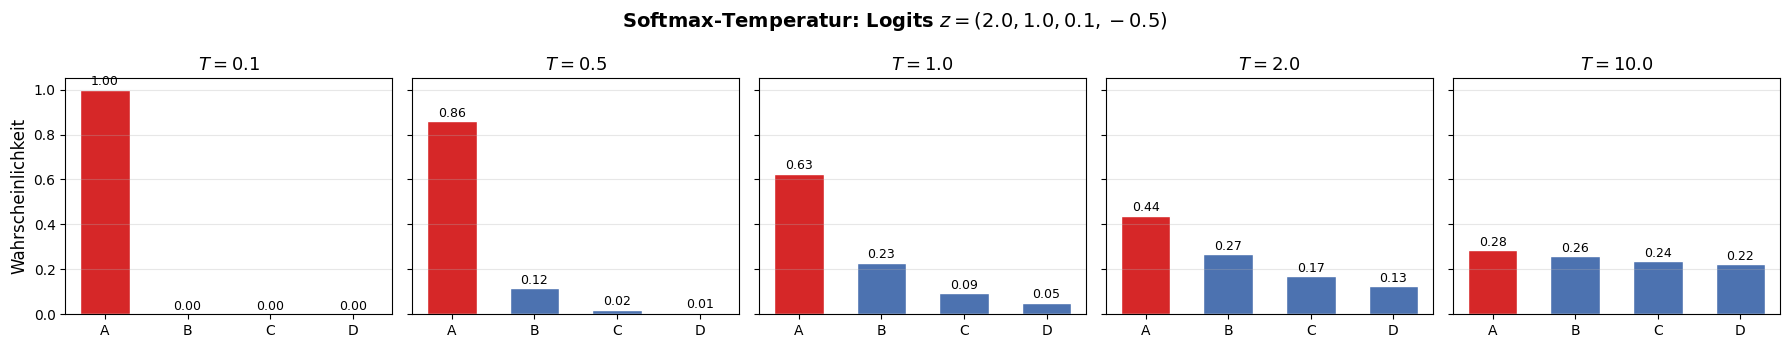

In [10]:
import matplotlib.pyplot as plt

def softmax_T(z, T):
    return softmax(z / T)

z = np.array([2.0, 1.0, 0.1, -0.5])
temperaturen = [0.1, 0.5, 1.0, 2.0, 10.0]
klassen = ["A", "B", "C", "D"]

fig, axes = plt.subplots(1, len(temperaturen), figsize=(18, 3.5), sharey=True)

for ax, T in zip(axes, temperaturen):
    probs = softmax_T(z, T)
    farben = ["#D62728" if p == probs.max() else "#4C72B0" for p in probs]
    ax.bar(klassen, probs, color=farben, edgecolor="white", width=0.6)
    ax.set_title(f"$T = {T}$", fontsize=13)
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3, axis="y")
    for i, p in enumerate(probs):
        ax.text(i, p + 0.02, f"{p:.2f}", ha="center", fontsize=9)

axes[0].set_ylabel("Wahrscheinlichkeit", fontsize=12)
fig.suptitle(f"Softmax-Temperatur: Logits $z = ({', '.join(f'{v:.1f}' for v in z)})$",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
logits = np.array([[2.0,  1.0, 0.1, -0.5],
                    [0.5,  0.5, 0.5,  0.5],     # alle gleich -> uniform
                    [-1.0, 3.0, -1.0, -1.0]])    # Klasse B dominant

probs = softmax(logits)
print(f"Softmax pro Zeile:\n{probs.round(4)}")
print(f"Zeilensummen: {probs.sum(axis=1).round(6)}")

Softmax pro Zeile:
[[0.6252 0.23   0.0935 0.0513]
 [0.25   0.25   0.25   0.25  ]
 [0.0174 0.9479 0.0174 0.0174]]
Zeilensummen: [1. 1. 1.]


#### Softmax + Cross-Entropy:

Im vorigen Notebook haben wir den Cross-Entropy Loss kennengelernt:

$$\mathcal{L} = -\log q_c \qquad \text{wobei } q_c = \text{softmax}(z_c)$$

Setzt man die Softmax-Definition ein:

$$\mathcal{L} = -\log \frac{e^{z_c}}{\sum_j e^{z_j}} = -z_c + \log \sum_j e^{z_j}$$

Der **LogSumExp**-Term $\log \sum e^{z_j}$ ist eine glatte Approximation an $\max(\mathbf{z})$. Die Verlustfunktion bestraft also: *"Wie weit liegt der Logit der richtigen Klasse unter dem Gesamtniveau?"*

In der Praxis werden Softmax und Cross-Entropy **immer zusammen** berechnet (als `softmax_cross_entropy` oder `F.cross_entropy`). Der Grund: Die kombinierte Berechnung ist numerisch stabiler und effizienter als die getrennte, weil teure `exp`/`log`-Paare sich teilweise aufheben.

In [12]:
def cross_entropy_loss(logits, targets):
    """L = -z_c + log(sum(exp(z))), numerisch stabil."""
    z_max = logits.max(axis=-1, keepdims=True)
    log_sum_exp = z_max.squeeze(-1) + np.log(np.exp(logits - z_max).sum(axis=-1))
    z_correct = logits[np.arange(len(targets)), targets]
    return (-z_correct + log_sum_exp).mean()

logits = np.array([[2.0, 1.0, 0.1, -0.5],
                    [0.5, 0.5, 0.5,  0.5],
                    [-1.0, 3.0, -1.0, -1.0]])
targets = np.array([0, 2, 1])  # wahre Klassen

probs = softmax(logits)
print(f"q(korrekte Klasse): {probs[np.arange(3), targets].round(4)}")

loss_a = -np.log(probs[np.arange(3), targets]).mean()  # via Softmax + -log
loss_b = cross_entropy_loss(logits, targets)             # direkt aus Logits
print(f"Loss (getrennt):  {loss_a:.6f}")
print(f"Loss (kombiniert): {loss_b:.6f}")
print(f"Identisch: {np.isclose(loss_a, loss_b)}")

q(korrekte Klasse): [0.6252 0.25   0.9479]
Loss (getrennt):  0.636499
Loss (kombiniert): 0.636499
Identisch: True


---

## Verständnis-Check

*Versuche die Fragen zu beantworten, bevor du die Lösungen aufdeckst.*

**Aufgabe 1:** Ein Tensor hat Shape `(2, 3, 4)`. (a) Wie viele Elemente enthält er? (b) Was ergibt `reshape(6, 4)`? (c) Was ergibt `sum(axis=1)`?

**Aufgabe 2:** $A$ hat Shape `(5, 3)`, $B$ hat Shape `(3, 7)`. Was ist der Shape von $A \cdot B$? Was, wenn $B$ Shape `(5, 7)` hätte?

**Aufgabe 3:** Berechne $\text{softmax}(1, 1, 1)$ von Hand. Was ergibt $\text{softmax}(z, z, z)$ für ein beliebiges $z$? Warum?

**Aufgabe 4:** Die Logits sind $\mathbf{z} = (3, 1, -2)$ und die wahre Klasse ist $c = 0$. Berechne den Cross-Entropy Loss $\mathcal{L} = -z_c + \log \sum e^{z_j}$.

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

(a) $2 \times 3 \times 4 = 24$ Elemente.

(b) `reshape(6, 4)` ist gültig, weil $6 \times 4 = 24$. Die Daten werden als 6 Zeilen à 4 Spalten interpretiert.

(c) `sum(axis=1)` summiert über die mittlere Dimension (Größe 3). Ergebnis-Shape: `(2, 4)`.
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

$A_{5 \times 3} \cdot B_{3 \times 7} = C_{5 \times 7}$ — die innere Dimension 3 stimmt überein.

Bei $B_{5 \times 7}$: Die inneren Dimensionen wären $3 \neq 5$ -> **nicht möglich**. Matmul erfordert, dass die letzte Dimension von $A$ gleich der vorletzten von $B$ ist.
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

$$\text{softmax}(1, 1, 1) = \frac{(e^1, e^1, e^1)}{3e^1} = \left(\frac{1}{3}, \frac{1}{3}, \frac{1}{3}\right)$$

Allgemein: $\text{softmax}(z, z, z) = (1/3, 1/3, 1/3)$ für jedes $z$, weil $\frac{e^z}{3 \cdot e^z} = 1/3$.

Softmax reagiert nur auf **Differenzen** zwischen den Logits, nicht auf ihr absolutes Niveau. Das ist konsistent mit dem Subtraktions-Trick für numerische Stabilität.
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

$$\mathcal{L} = -z_0 + \log(e^3 + e^1 + e^{-2})$$

$$= -3 + \log(20{,}086 + 2{,}718 + 0{,}135)$$

$$= -3 + \log(22{,}939)$$

$$= -3 + 3{,}132 = 0{,}132 \text{ Nat}$$

Der Loss ist niedrig, weil der Logit der richtigen Klasse ($z_0 = 3$) deutlich dominiert.
</details>

## Zusammenfassung

Ein **Tensor** ist ein mehrdimensionales Zahlengitter. Shape und Rang beschreiben seine Struktur, die Daten selbst liegen sequenziell im Speicher. **Reshape** ändert nur die Interpretation dieser Sequenz.

**Elementweise Operationen** arbeiten unabhängig pro Element. **Broadcasting** erlaubt es, Tensoren mit unterschiedlichen (aber kompatiblen) Shapes zu kombinieren, indem Dimensionen der Größe 1 logisch wiederholt werden. Das eliminiert explizite Schleifen und ist der Grund, warum ML-Code so kompakt sein kann.

Die **Matrixmultiplikation** ist die Kernoperation: $c_{ij} = \sum_k a_{ik} b_{kj}$. Jede lineare Schicht ist ein Matmul plus Bias. Batched Matmul verarbeitet viele Datenpunkte parallel. Für eine lineare Schicht: $Y = X W + \mathbf{b}$ — Eingabe $(B, D)$, Gewichte $(D, K)$, Ergebnis $(B, K)$.

**Reduktionen** summieren, mitteln oder maximieren entlang einer Achse und eliminieren diese Dimension. `keepdims=True` bewahrt die Form für anschließendes Broadcasting.

**Softmax** wandelt rohe Logits $z$ in eine Wahrscheinlichkeitsverteilung um: $q_i = e^{z_i} / \sum e^{z_j}$. Die stabile Version subtrahiert $\max(z)$ vor der Exponentiation. Zusammen mit dem Cross-Entropy Loss ergibt sich die Standardverlustfunktion für Klassifikation: $\mathcal{L} = -z_c + \log \sum e^{z_j}$.

| Operation | Formel | Shape-Regel |
|-----------|--------|-------------|
| **Reshape** | Gleiche Daten, andere Interpretation | $\prod d_i = \prod d_i'$ |
| **Elementwise** | $f(A)_{ij} = f(a_{ij})$ | Shapes gleich oder broadcastbar |
| **Broadcasting** | Dimension 1 wird wiederholt | Von rechts vergleichen |
| **Matmul** | $c_{ij} = \sum_k a_{ik} b_{kj}$ | $(m, \mathbf{n}) \times (\mathbf{n}, p) = (m, p)$ |
| **Reduktion** | z.B. $\sum_i a_{ij}$ | Eliminiert die `axis`-Dimension |
| **Softmax** | $\frac{e^{z_i}}{\sum e^{z_j}}$ | Shape bleibt gleich |

> **Nächster Schritt:** Die Logits kommen nicht aus dem Nichts - sie entstehen durch Gewichte, die *gelernt* werden. Wie? Über Gradienten. -> Weiter zu [03 - Optimierung und Backpropagation](03_Optimierung_und_Backpropagation.ipynb)

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Tensor | Tensor |
| Rang (Dimensionalität) | Rank / ndim |
| Form | Shape |
| Umformen | Reshape |
| Elementweise Operation | Elementwise / pointwise operation |
| Hadamard-Produkt | Hadamard product / elementwise multiply |
| Broadcasting | Broadcasting |
| Matrixmultiplikation | Matrix multiplication / matmul |
| Stapelverarbeitung | Batched computation |
| Reduktion | Reduction |
| Logit | Logit |
| Softmax | Softmax |
| Temperatur | Temperature |
| Numerische Stabilität | Numerical stability |
| Log-Sum-Exp | Log-sum-exp |